import libraries

In [13]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph
from IPython.display import Image, display

create state

In [2]:
class PortfoliState(TypedDict):
    amount_usd:float
    total_usd:float
    total_inr:float

create functions for nodes

In [3]:
def cal_total_usd(state:PortfoliState):
    amount_usd= state['amount_usd']
    total_usd = amount_usd*1.08
    state['total_usd']=total_usd
    return state

In [4]:
def cal_total_inr(state:PortfoliState):
    total_usd= state['total_usd']
    total_inr = total_usd*86
    state['total_inr']=total_inr
    return state

create graph

In [7]:
graph = StateGraph(PortfoliState)

Create nodes

In [8]:
graph.add_node("calculate_amount", cal_total_usd)
graph.add_node("calculate_inr",cal_total_inr)

create edges

In [9]:
graph.add_edge(START, "calculate_amount")
graph.add_edge("calculate_amount","calculate_inr")
graph.add_edge("calculate_inr",END)

Compile Graph

In [10]:
workflow=graph.compile()

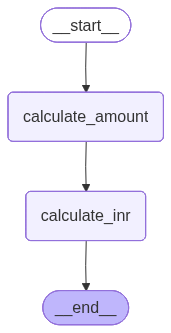

In [17]:
Image(workflow.get_graph().draw_mermaid_png())

In [18]:
initial_state={"amount_usd":200}
final_state= workflow.invoke(initial_state)
print(final_state)

{'amount_usd': 200, 'total_usd': 216.0, 'total_inr': 18576.0}
